# Digital Image Processing Project

**University Project – Digital Image Processing Laboratory**

This notebook presents a reimplementation of the original university Digital Image Processing project based on the official course assignment.

The project covers fundamental image-processing techniques including color-space analysis, grayscale and binary conversion, histogram-based segmentation, geometric transformations, Gaussian noise, spatial filtering, connected-component labeling, and frequency-domain periodic-noise removal.

The implementation is intentionally kept close to the educational scope of the original assignment.

## 1. Project Objectives

The main objectives of this project are:

- Analyze RGB and HSV image channels.
- Convert RGB images to grayscale and binary representations.
- Use grayscale histograms for threshold-based segmentation.
- Apply basic geometric image transformations.
- Add Gaussian noise with a standard deviation of 50.
- Implement a 5×5 averaging filter manually.
- Compare the manual result with `scipy.ndimage.convolve`.
- Apply connected-component labeling using 8-connectivity.
- Extract South America from the noisy world-map image.
- Analyze periodic noise in the frequency domain.
- Remove periodic noise using a Butterworth notch-reject filter.

---

## 2. Imports and Configuration

NumPy is used for numerical operations, Matplotlib for visualization, Pillow for image manipulation, and SciPy for convolution and connected-component analysis.

A fixed random seed is used where random values are generated so that the notebook remains reproducible.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from scipy import ndimage

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Resolve repository paths whether the notebook is launched from the repository
# root or directly from the notebooks/ directory.
cwd = Path.cwd()
if (cwd / "images").exists():
    REPO_ROOT = cwd
elif (cwd.parent / "images").exists():
    REPO_ROOT = cwd.parent
else:
    REPO_ROOT = Path("..").resolve()

IMAGES_DIR = REPO_ROOT / "images"
RESULTS_DIR = REPO_ROOT / "results"

for folder in [
    RESULTS_DIR / "transformations",
    RESULTS_DIR / "segmentation",
    RESULTS_DIR / "filtering",
    RESULTS_DIR / "frequency_domain",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Repository root:", REPO_ROOT.resolve())
print("Images directory:", IMAGES_DIR.resolve())

Repository root: C:\Users\arion\Desktop\GitHub Projects\digital-image-processing-project
Images directory: C:\Users\arion\Desktop\GitHub Projects\digital-image-processing-project\images


---

## 3. Input Images

The project uses the two images included with the original university assignment:

- `aloe-plant-pot.jpg`
- `noise_world_map.png`

The images are loaded and inspected before processing.

Aloe image:
  shape: (1364, 1000, 3)
  dtype: uint8

World-map image:
  shape: (434, 654, 3)
  dtype: uint8


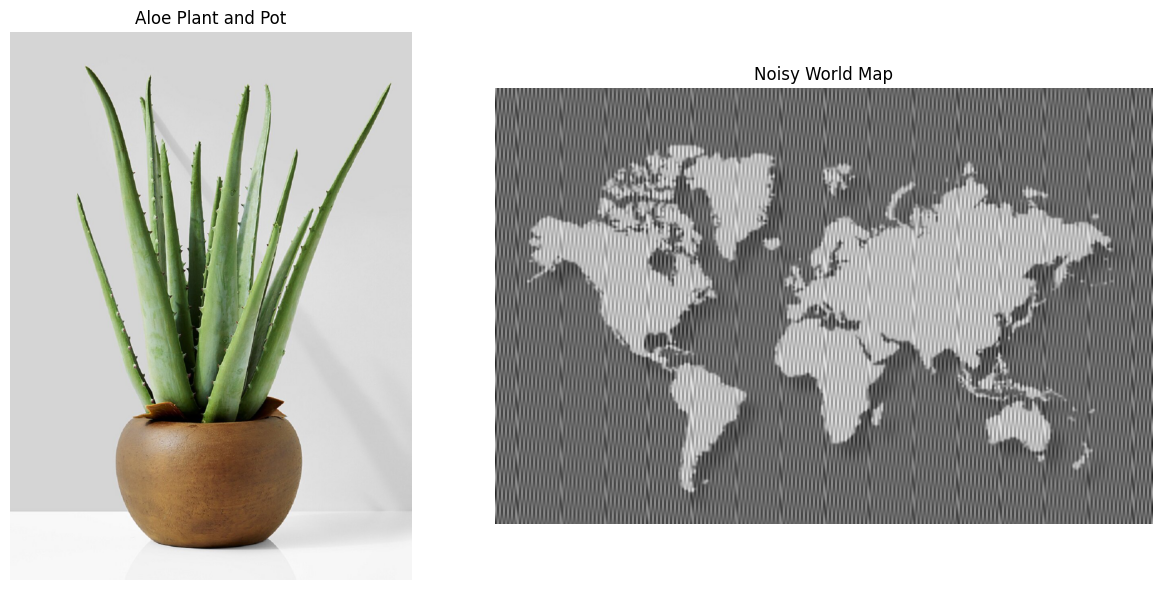

In [2]:
aloe_pil = Image.open(IMAGES_DIR / "aloe-plant-pot.jpg").convert("RGB")
world_pil = Image.open(IMAGES_DIR / "noise_world_map.png").convert("RGB")

aloe_rgb = np.asarray(aloe_pil)
world_rgb = np.asarray(world_pil)

print("Aloe image:")
print("  shape:", aloe_rgb.shape)
print("  dtype:", aloe_rgb.dtype)

print("\nWorld-map image:")
print("  shape:", world_rgb.shape)
print("  dtype:", world_rgb.dtype)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(aloe_rgb)
axes[0].set_title("Aloe Plant and Pot")
axes[0].axis("off")

axes[1].imshow(world_rgb)
axes[1].set_title("Noisy World Map")
axes[1].axis("off")

plt.tight_layout()
plt.show()

---

# 4. Question 1 — Color Spaces and Image Conversion

The first part of the assignment examines different representations of the aloe image.

The RGB channels are displayed separately, the image is converted to HSV, and grayscale and binary representations are produced.

## 4.1 RGB Channels

An RGB image consists of three channels: red, green, and blue.  
Each channel represents the intensity contribution of the corresponding color component.

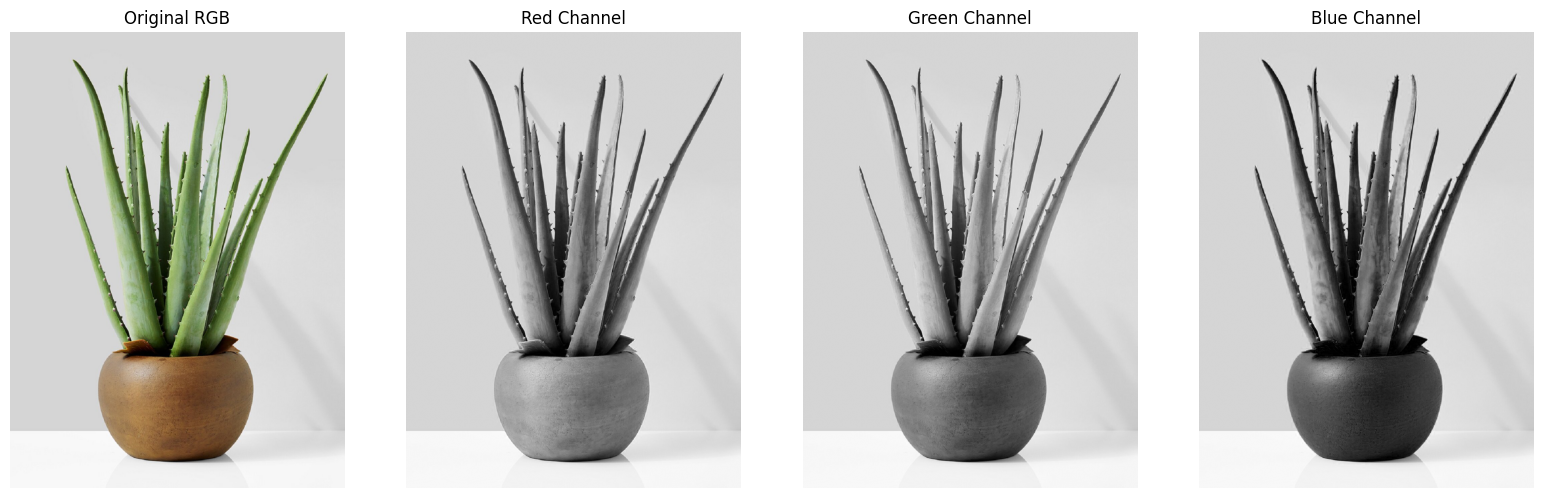

In [3]:
red = aloe_rgb[:, :, 0]
green = aloe_rgb[:, :, 1]
blue = aloe_rgb[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(aloe_rgb)
axes[0].set_title("Original RGB")

axes[1].imshow(red, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Red Channel")

axes[2].imshow(green, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Green Channel")

axes[3].imshow(blue, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Blue Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4.2 HSV Color Space

HSV separates color information into:

- **Hue** — dominant color information,
- **Saturation** — color intensity or purity,
- **Value** — image brightness.

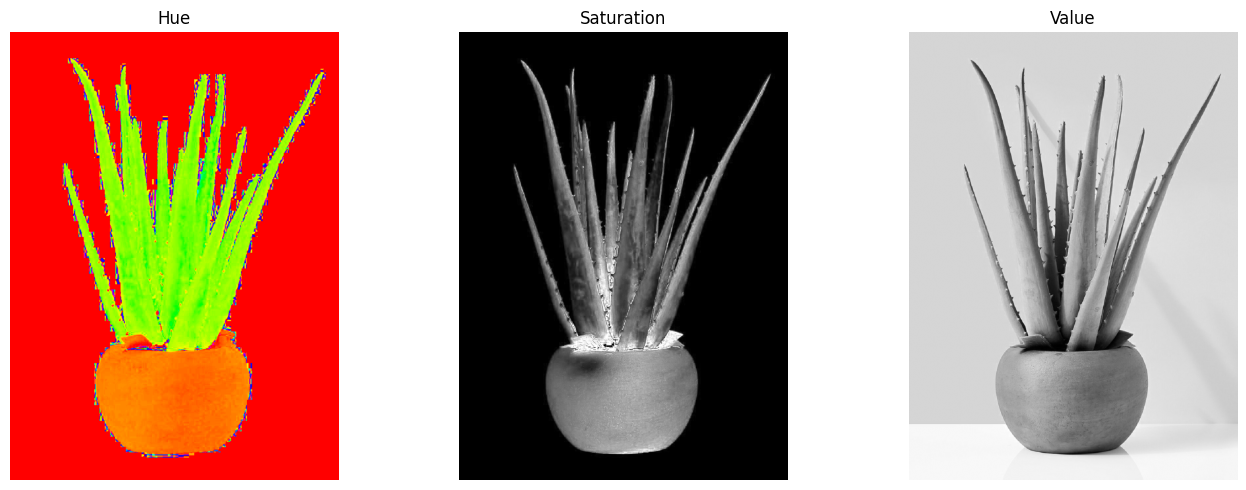

In [4]:
# Pillow uses 0-255 ranges for the converted HSV image.
aloe_hsv = np.asarray(aloe_pil.convert("HSV"))

hue = aloe_hsv[:, :, 0]
saturation = aloe_hsv[:, :, 1]
value = aloe_hsv[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(hue, cmap="hsv")
axes[0].set_title("Hue")

axes[1].imshow(saturation, cmap="gray")
axes[1].set_title("Saturation")

axes[2].imshow(value, cmap="gray")
axes[2].set_title("Value")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4.3 Grayscale Conversion

The RGB image is converted to grayscale.  
The grayscale result is reused in the following questions.

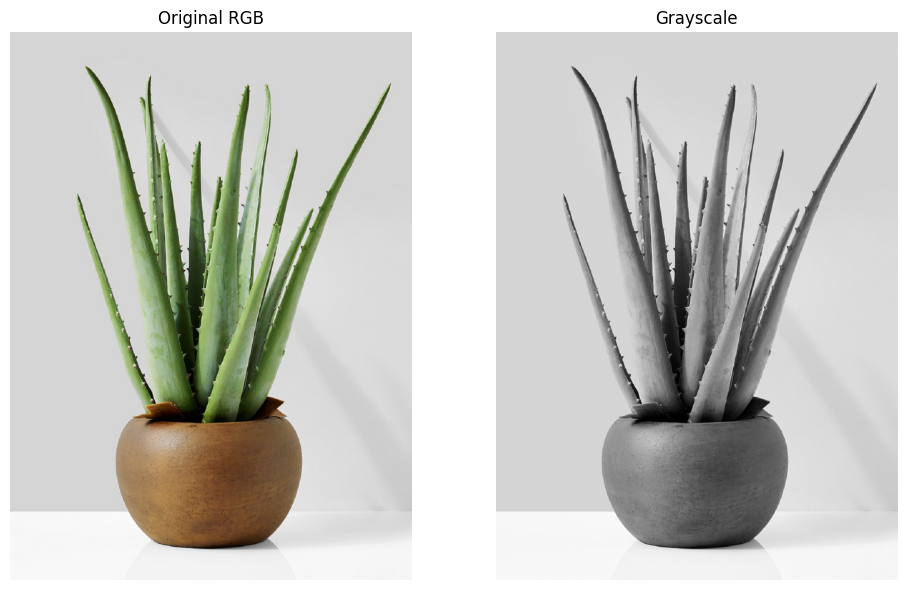

In [5]:
aloe_gray_pil = aloe_pil.convert("L")
aloe_gray = np.asarray(aloe_gray_pil)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].imshow(aloe_rgb)
axes[0].set_title("Original RGB")
axes[0].axis("off")

axes[1].imshow(aloe_gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 4.4 Binary Image Conversion

A binary image contains only two pixel classes.  
For this introductory binary conversion, a fixed global threshold is used.

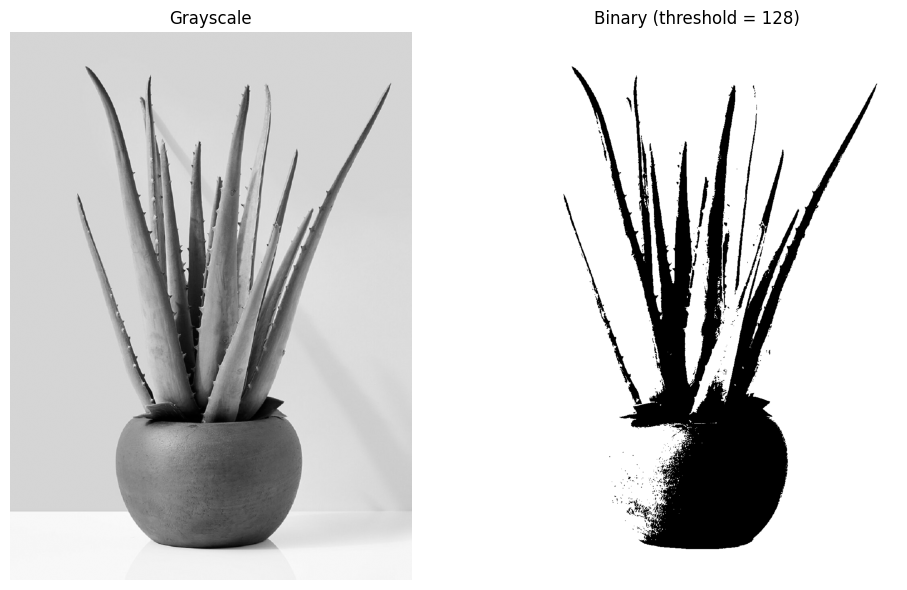

In [6]:
BINARY_THRESHOLD = 128
aloe_binary = (aloe_gray >= BINARY_THRESHOLD).astype(np.uint8) * 255

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].imshow(aloe_gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Grayscale")
axes[0].axis("off")

axes[1].imshow(aloe_binary, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Binary (threshold = {BINARY_THRESHOLD})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

---

# 5. Question 2 — Histogram and Pot Segmentation

The grayscale histogram is used to inspect the distribution of image intensities.

A practical intensity range is then selected to isolate the darker pot region.  
Because thresholding alone may also select dark leaf or shadow pixels, connected-component cleanup is used only to keep the dominant pot-region candidate in the lower part of the image.

## 5.1 Grayscale Histogram

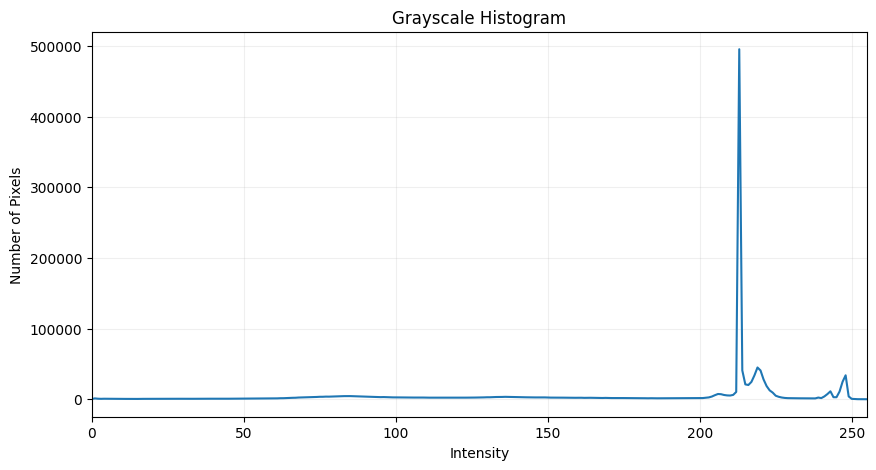

In [7]:
hist, bins = np.histogram(aloe_gray.ravel(), bins=256, range=(0, 256))

plt.figure(figsize=(10, 5))
plt.plot(hist)
plt.title("Grayscale Histogram")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")
plt.xlim(0, 255)
plt.grid(alpha=0.2)
plt.show()

## 5.2 Threshold Selection

The pot is substantially darker than the white background.  
A lower-intensity range is therefore used to create an initial segmentation mask.

The values below are kept explicit so that they can be inspected and adjusted if the input image is replaced.

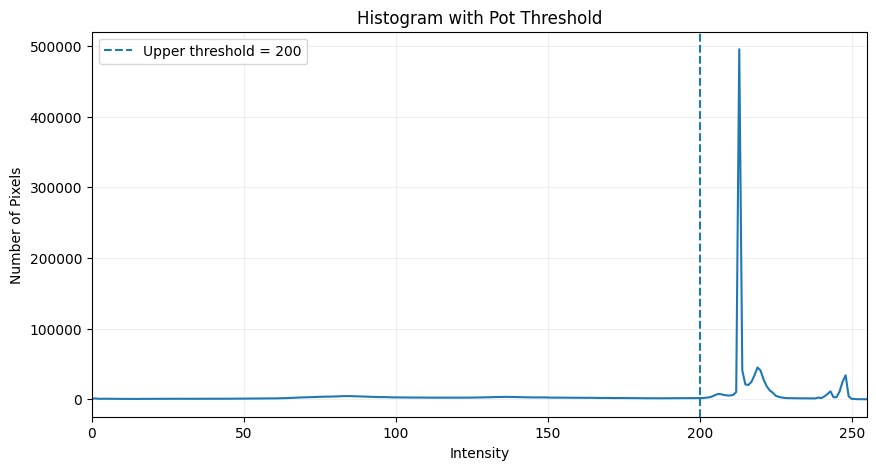

In [8]:
POT_UPPER = 200

plt.figure(figsize=(10, 5))
plt.plot(hist)
plt.axvline(POT_UPPER, linestyle="--", label=f"Upper threshold = {POT_UPPER}")
plt.title("Histogram with Pot Threshold")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")
plt.xlim(0, 255)
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## 5.3 Pot Segmentation Mask

The initial threshold mask is restricted to the lower part of the image, where the pot is located.  
The largest connected candidate in that region is retained and lightly cleaned.

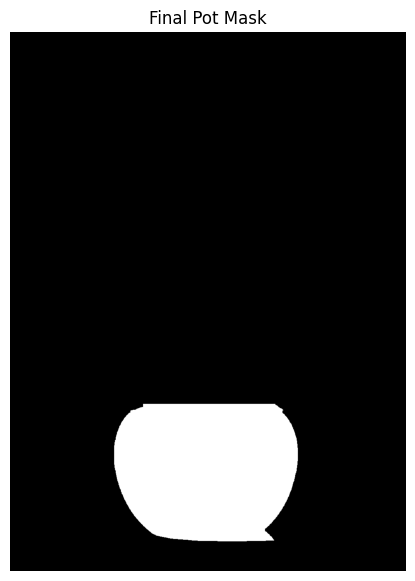

In [9]:
# The pot is located in the lower part of the image and is darker than the background.
initial_pot_mask = aloe_gray < POT_UPPER

roi = np.zeros_like(initial_pot_mask, dtype=bool)
roi[int(aloe_gray.shape[0] * 0.69):,
    int(aloe_gray.shape[1] * 0.20):int(aloe_gray.shape[1] * 0.80)] = True

pot_candidate = initial_pot_mask & roi

# Close small holes/gaps before connected-component selection.
pot_candidate = ndimage.binary_closing(
    pot_candidate,
    structure=np.ones((5, 5), dtype=bool),
    iterations=1
)

labels, num_labels = ndimage.label(
    pot_candidate,
    structure=np.ones((3, 3), dtype=int)
)

sizes = ndimage.sum(
    pot_candidate,
    labels,
    index=np.arange(1, num_labels + 1)
)

if num_labels == 0:
    raise RuntimeError("No pot candidate was detected.")

largest_label = int(np.argmax(sizes)) + 1
pot_mask = labels == largest_label

plt.figure(figsize=(6, 7))
plt.imshow(pot_mask, cmap="gray")
plt.title("Final Pot Mask")
plt.axis("off")
plt.show()


## 5.4 Pot Extraction

The mask is applied to the original RGB image.  
Pixels outside the selected pot region are replaced with white.

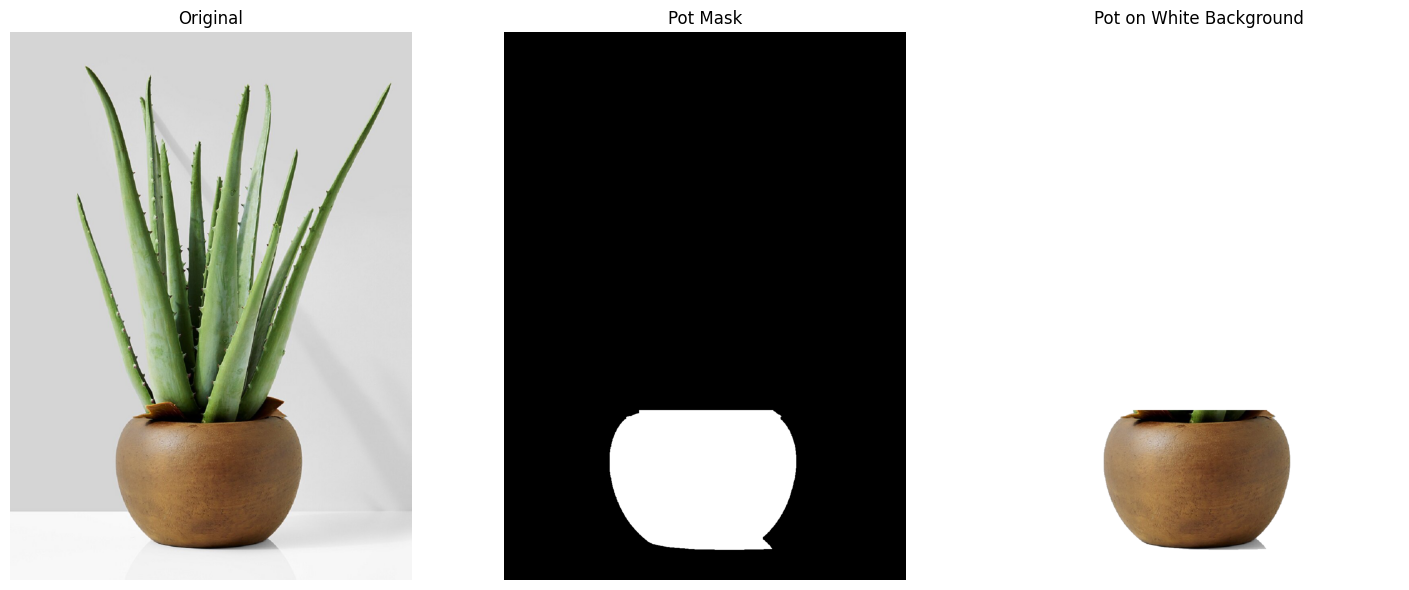

In [10]:
pot_only = np.full_like(aloe_rgb, 255)
pot_only[pot_mask] = aloe_rgb[pot_mask]

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(aloe_rgb)
axes[0].set_title("Original")

axes[1].imshow(pot_mask, cmap="gray")
axes[1].set_title("Pot Mask")

axes[2].imshow(pot_only)
axes[2].set_title("Pot on White Background")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Image.fromarray(pot_only).save(RESULTS_DIR / "segmentation" / "pot_segmentation.png")

---

# 6. Question 3 — Geometric Image Transformations

The grayscale image is transformed using:

1. transposition,
2. resizing to 300 × 255 pixels,
3. 45° counter-clockwise rotation.

## 6.1 Image Transposition

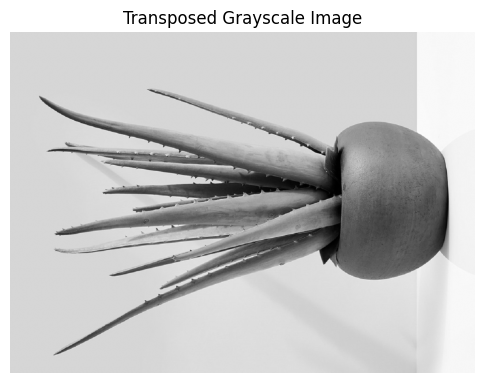

In [11]:
aloe_transposed = aloe_gray.T

plt.figure(figsize=(6, 7))
plt.imshow(aloe_transposed, cmap="gray")
plt.title("Transposed Grayscale Image")
plt.axis("off")
plt.show()

Image.fromarray(aloe_transposed).save(
    RESULTS_DIR / "transformations" / "grayscale_transposed.png"
)

## 6.2 Image Resizing

The image is resized to **300 × 255 pixels** using Pillow.  
Pillow expects the size in `(width, height)` order.

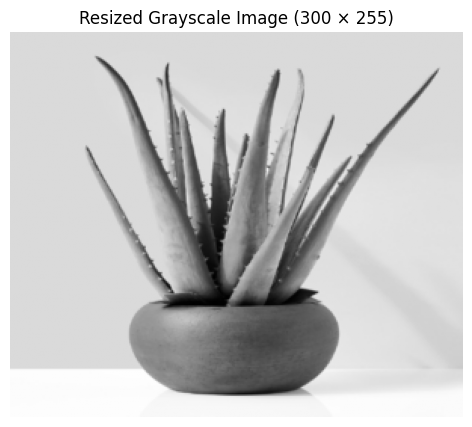

In [12]:
aloe_resized_pil = aloe_gray_pil.resize((300, 255), Image.Resampling.BILINEAR)
aloe_resized = np.asarray(aloe_resized_pil)

plt.figure(figsize=(6, 5))
plt.imshow(aloe_resized, cmap="gray")
plt.title("Resized Grayscale Image (300 × 255)")
plt.axis("off")
plt.show()

aloe_resized_pil.save(
    RESULTS_DIR / "transformations" / "grayscale_resized.png"
)

## 6.3 Image Rotation

The grayscale image is rotated **45° counter-clockwise**.  
`expand=True` is used so that the full rotated image remains visible.

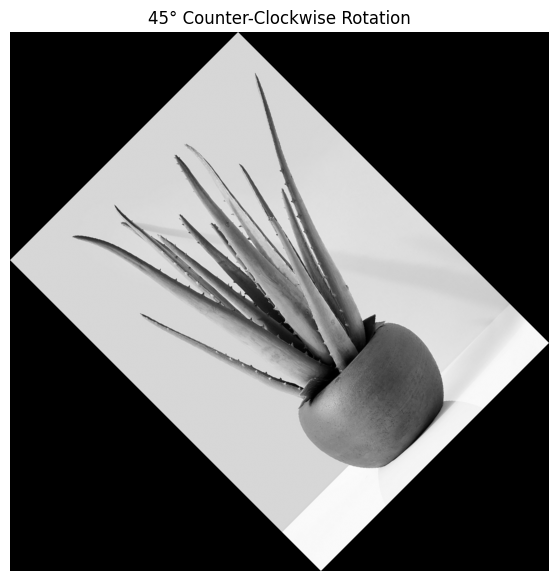

In [13]:
aloe_rotated_pil = aloe_gray_pil.rotate(45, expand=True, resample=Image.Resampling.BILINEAR)
aloe_rotated = np.asarray(aloe_rotated_pil)

plt.figure(figsize=(7, 7))
plt.imshow(aloe_rotated, cmap="gray")
plt.title("45° Counter-Clockwise Rotation")
plt.axis("off")
plt.show()

aloe_rotated_pil.save(
    RESULTS_DIR / "transformations" / "grayscale_rotated_45.png"
)

## 6.4 Transformation Comparison

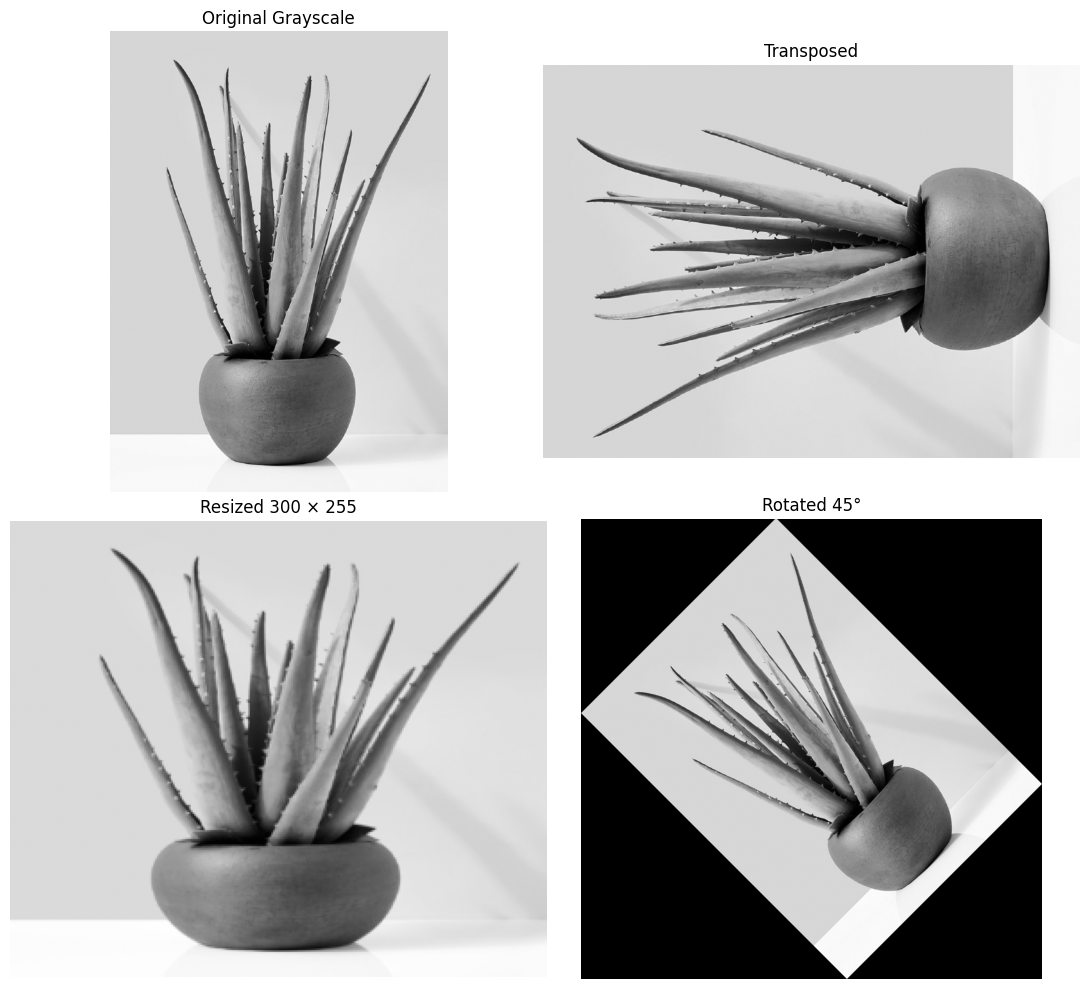

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))

axes[0, 0].imshow(aloe_gray, cmap="gray")
axes[0, 0].set_title("Original Grayscale")

axes[0, 1].imshow(aloe_transposed, cmap="gray")
axes[0, 1].set_title("Transposed")

axes[1, 0].imshow(aloe_resized, cmap="gray")
axes[1, 0].set_title("Resized 300 × 255")

axes[1, 1].imshow(aloe_rotated, cmap="gray")
axes[1, 1].set_title("Rotated 45°")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

---

# 7. Question 4 — Gaussian Noise

Gaussian noise is added to the grayscale image with:

\[
\mu = 0,\qquad \sigma = 50
\]

The resulting values are clipped to the valid 8-bit intensity range \([0,255]\).

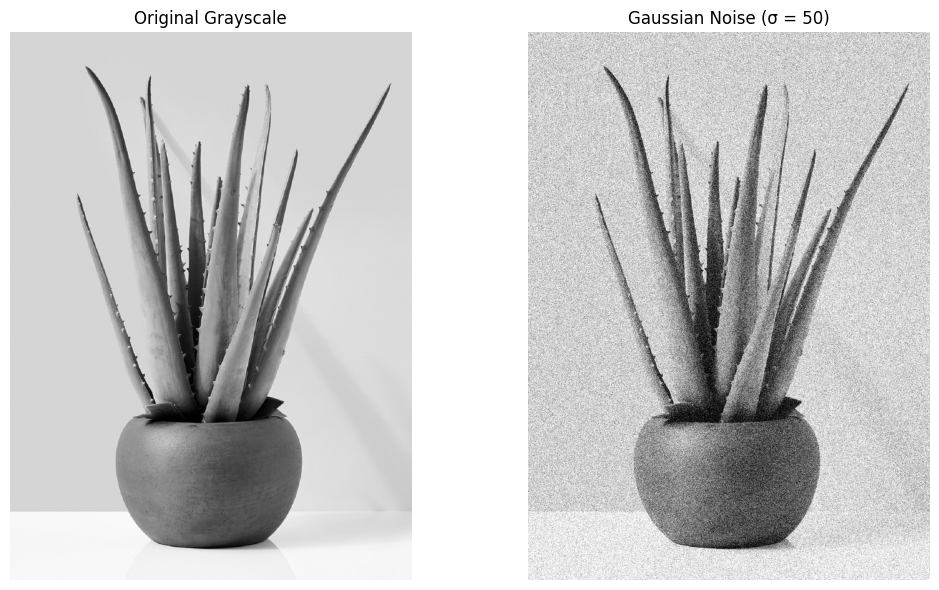

In [15]:
GAUSSIAN_STD = 50.0

noise = rng.normal(loc=0.0, scale=GAUSSIAN_STD, size=aloe_gray.shape)
aloe_noisy = aloe_gray.astype(np.float64) + noise
aloe_noisy = np.clip(aloe_noisy, 0, 255)

fig, axes = plt.subplots(1, 2, figsize=(11, 6))

axes[0].imshow(aloe_gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Grayscale")

axes[1].imshow(aloe_noisy, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Gaussian Noise (σ = 50)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Image.fromarray(aloe_noisy.astype(np.uint8)).save(
    RESULTS_DIR / "filtering" / "gaussian_noise_std50.png"
)

---

# 8. Question 5 — Manual 5×5 Mean Filtering

The assignment refers to a 5×5 mean filter and then requires the same mask to be reused with convolution.

For this reason, the filter is implemented as a **5×5 arithmetic averaging filter**.

This section performs the filtering manually, without using a ready-made convolution function.

## 8.1 Mean Filter Kernel

\[
H =
\frac{1}{25}
\begin{bmatrix}
1 & 1 & 1 & 1 & 1\\
1 & 1 & 1 & 1 & 1\\
1 & 1 & 1 & 1 & 1\\
1 & 1 & 1 & 1 & 1\\
1 & 1 & 1 & 1 & 1
\end{bmatrix}
\]

In [16]:
mean_kernel = np.ones((5, 5), dtype=np.float64) / 25.0
print(mean_kernel)

[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]


## 8.2 Manual Filtering Implementation

For each output pixel:

1. a 5×5 neighborhood is selected,
2. the neighborhood is multiplied by the averaging mask,
3. the weighted values are summed,
4. the result is assigned to the output pixel.

Reflective padding is used so that the output image keeps the same dimensions.

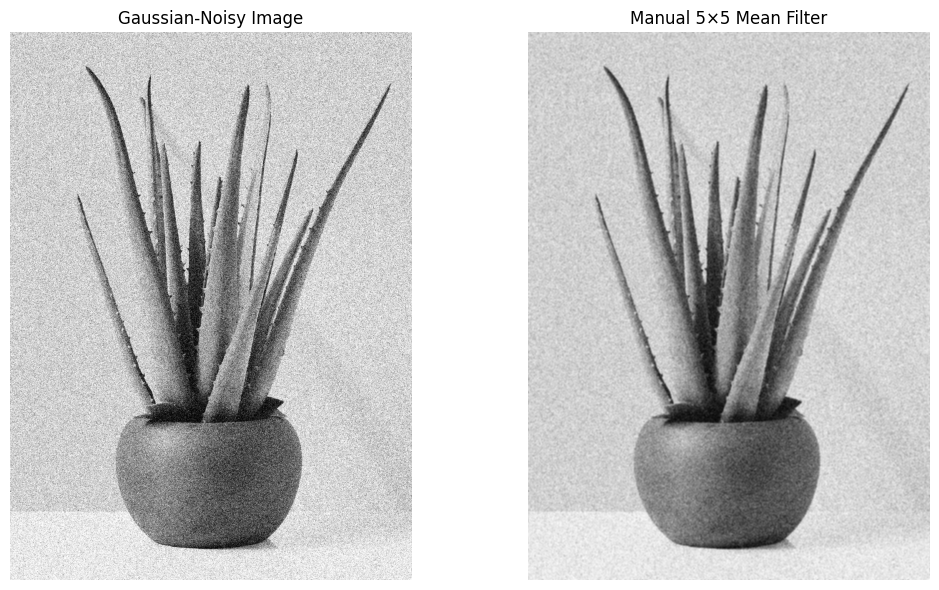

In [17]:
def manual_convolve_2d(image, kernel):
    image = image.astype(np.float64)
    kernel = kernel.astype(np.float64)

    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="symmetric"
    )

    output = np.zeros_like(image, dtype=np.float64)

    # Educational implementation: explicit neighborhood processing.
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            region = padded[row:row + kh, col:col + kw]
            output[row, col] = np.sum(region * kernel)

    return output


manual_filtered = manual_convolve_2d(aloe_noisy, mean_kernel)

fig, axes = plt.subplots(1, 2, figsize=(11, 6))

axes[0].imshow(aloe_noisy, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Gaussian-Noisy Image")

axes[1].imshow(manual_filtered, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Manual 5×5 Mean Filter")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Image.fromarray(np.clip(manual_filtered, 0, 255).astype(np.uint8)).save(
    RESULTS_DIR / "filtering" / "manual_mean_filter_5x5.png"
)

---

# 9. Question 6 — Filtering with `scipy.ndimage.convolve`

The same 5×5 averaging mask is applied to the noisy image using SciPy.

The result is compared with the manual implementation.

In [18]:
scipy_filtered = ndimage.convolve(
    aloe_noisy,
    mean_kernel,
    mode="reflect"
)

Image.fromarray(np.clip(scipy_filtered, 0, 255).astype(np.uint8)).save(
    RESULTS_DIR / "filtering" / "scipy_mean_filter_5x5.png"
)

difference = np.abs(manual_filtered - scipy_filtered)

print("Maximum absolute difference:", float(difference.max()))
print("Mean absolute difference:", float(difference.mean()))

Maximum absolute difference: 1.7053025658242404e-13
Mean absolute difference: 2.6144282568123855e-14


## 9.1 Required 2×2 Filtering Comparison

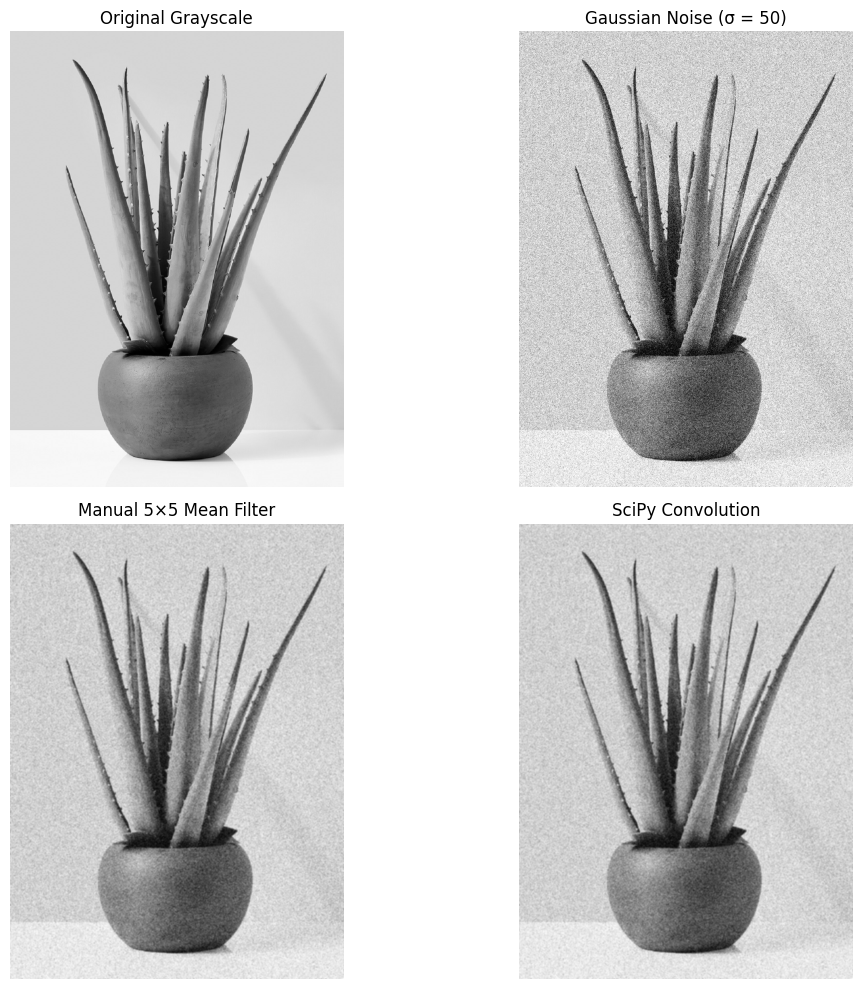

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(aloe_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Grayscale")

axes[0, 1].imshow(aloe_noisy, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Gaussian Noise (σ = 50)")

axes[1, 0].imshow(manual_filtered, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Manual 5×5 Mean Filter")

axes[1, 1].imshow(scipy_filtered, cmap="gray", vmin=0, vmax=255)
axes[1, 1].set_title("SciPy Convolution")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()

comparison_path = RESULTS_DIR / "filtering" / "filtering_comparison.png"
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

---

# 10. Question 7 — South America Extraction Using Connected Components

The world-map image is processed so that South America can be isolated.

The assignment explicitly requests connected-component labeling with **8-connectivity**.

## 10.1 World Map Preprocessing

The RGB world-map image is converted to grayscale.  
A mild Gaussian filter reduces the high-frequency periodic pattern enough to make continent segmentation more stable.

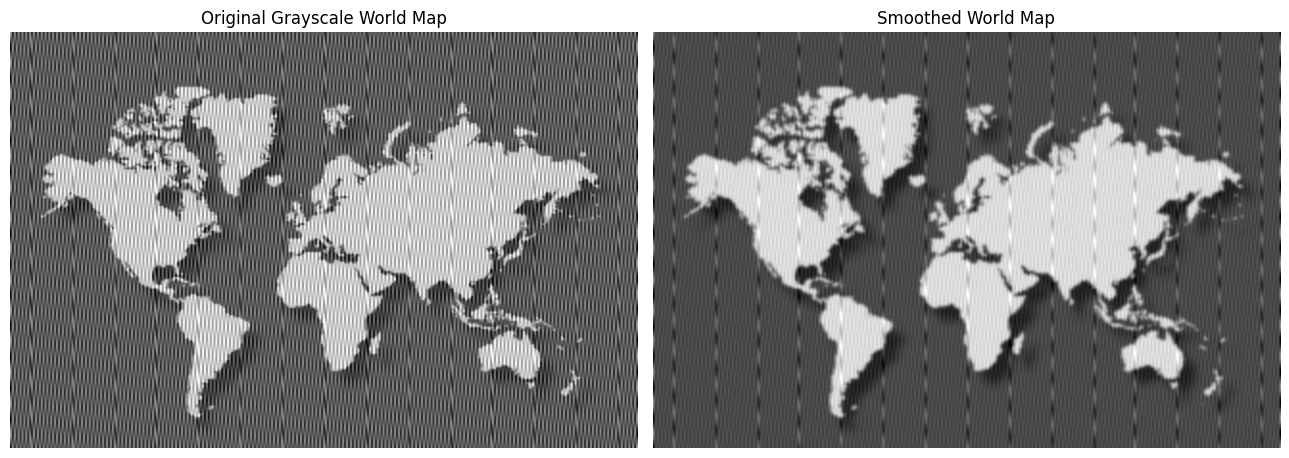

In [20]:
world_gray = np.asarray(Image.fromarray(world_rgb).convert("L")).astype(np.float64)

world_smooth = ndimage.gaussian_filter(world_gray, sigma=1.2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(world_gray, cmap="gray")
axes[0].set_title("Original Grayscale World Map")

axes[1].imshow(world_smooth, cmap="gray")
axes[1].set_title("Smoothed World Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.2 Binary Segmentation

The continents are darker than the white background.  
A threshold is therefore used to obtain a binary land mask.

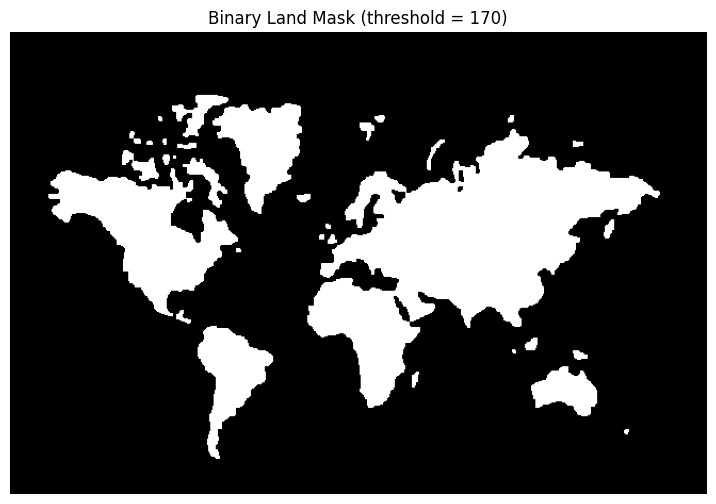

In [21]:
WORLD_THRESHOLD = 170

# The continents are the bright regions of the provided world-map image.
land_mask = world_smooth > WORLD_THRESHOLD

land_mask = ndimage.binary_opening(
    land_mask,
    structure=np.ones((3, 3), dtype=bool),
    iterations=1
)
land_mask = ndimage.binary_closing(
    land_mask,
    structure=np.ones((3, 3), dtype=bool),
    iterations=1
)

plt.figure(figsize=(10, 6))
plt.imshow(land_mask, cmap="gray")
plt.title(f"Binary Land Mask (threshold = {WORLD_THRESHOLD})")
plt.axis("off")
plt.show()


## 10.3 8-Connectivity and Connected-Component Labeling

With 8-connectivity, horizontal, vertical, and diagonal neighboring pixels are treated as connected.

The connectivity structure is:

\[
\begin{bmatrix}
1 & 1 & 1\\
1 & 1 & 1\\
1 & 1 & 1
\end{bmatrix}
\]

Detected components: 32


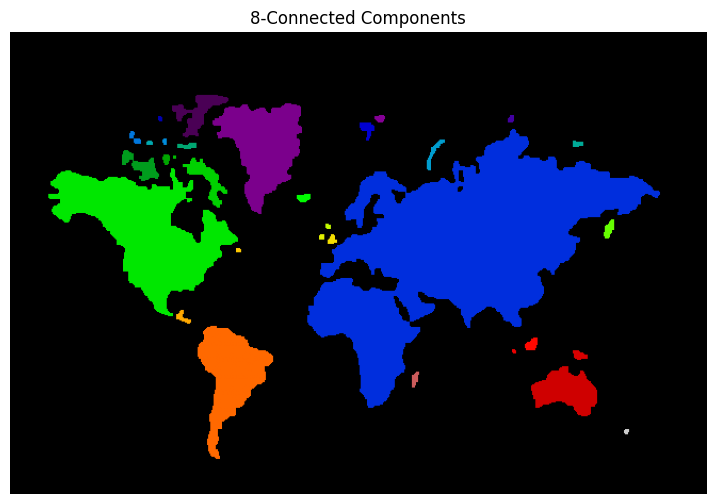

In [22]:
connectivity_8 = np.ones((3, 3), dtype=int)

world_labels, world_num_labels = ndimage.label(
    land_mask,
    structure=connectivity_8
)

component_sizes = ndimage.sum(
    land_mask,
    world_labels,
    index=np.arange(1, world_num_labels + 1)
)

print("Detected components:", world_num_labels)

plt.figure(figsize=(10, 6))
plt.imshow(world_labels, cmap="nipy_spectral")
plt.title("8-Connected Components")
plt.axis("off")
plt.show()

## 10.4 South America Component Selection

South America is located in the lower-middle part of the world map.

To keep the selection reproducible and still based on connected-component labeling, the component containing a known interior coordinate of South America is selected.

Selected South America label: 26
South America component pixels: 3984


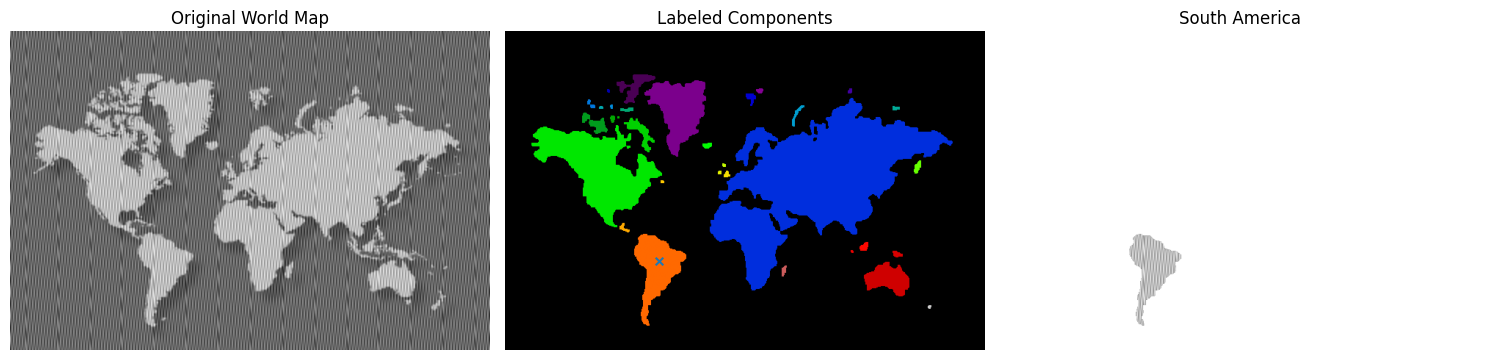

In [23]:
h, w = world_labels.shape

# Interior reference point for South America in the provided assignment image.
south_america_point = (
    int(h * 0.72),
    int(w * 0.32),
)

south_america_label = int(world_labels[south_america_point])

if south_america_label == 0:
    r, c = south_america_point
    r0, r1 = max(0, r - 25), min(h, r + 26)
    c0, c1 = max(0, c - 25), min(w, c + 26)

    nearby = world_labels[r0:r1, c0:c1]
    nearby_labels, counts = np.unique(nearby[nearby > 0], return_counts=True)

    if len(nearby_labels) == 0:
        raise RuntimeError("South America component could not be located.")

    south_america_label = int(nearby_labels[np.argmax(counts)])

south_america_mask = world_labels == south_america_label

south_america_result = np.full(world_gray.shape, 255, dtype=np.uint8)
south_america_result[south_america_mask] = np.clip(
    world_gray[south_america_mask], 0, 255
).astype(np.uint8)

print("Selected South America label:", south_america_label)
print("South America component pixels:", int(south_america_mask.sum()))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(world_rgb)
axes[0].set_title("Original World Map")

axes[1].imshow(world_labels, cmap="nipy_spectral")
axes[1].scatter(
    south_america_point[1],
    south_america_point[0],
    s=30,
    marker="x"
)
axes[1].set_title("Labeled Components")

axes[2].imshow(south_america_result, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("South America")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Image.fromarray(south_america_result).save(
    RESULTS_DIR / "segmentation" / "south_america_extraction.png"
)


---

# 11. Question 8 — Periodic Noise Removal in the Frequency Domain

Periodic interference produces characteristic frequency components in the Fourier spectrum.

The world-map image is transformed to the frequency domain, the periodic-noise peaks are identified, and a Butterworth notch-reject filter is applied.

## 11.1 Two-Dimensional Fourier Transform

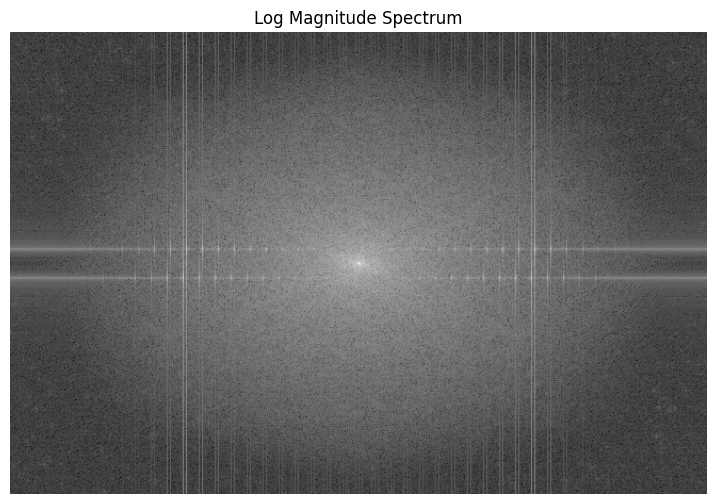

In [24]:
world_fft = np.fft.fft2(world_gray)
world_fft_shifted = np.fft.fftshift(world_fft)

world_magnitude = np.log1p(np.abs(world_fft_shifted))

plt.figure(figsize=(10, 6))
plt.imshow(world_magnitude, cmap="gray")
plt.title("Log Magnitude Spectrum")
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 6))
plt.imshow(world_magnitude, cmap="gray")
plt.title("Original Frequency Spectrum")
plt.axis("off")
plt.savefig(
    RESULTS_DIR / "frequency_domain" / "original_frequency_spectrum.png",
    dpi=150,
    bbox_inches="tight"
)
plt.close()

## 11.2 Periodic-Noise Peak Detection

Periodic interference appears in the Fourier spectrum as strong frequency components away from the central low-frequency region.

The central region is excluded from the peak search so that the dominant image structure is not mistaken for noise. Local maxima are then detected and grouped into symmetric frequency pairs, since the Fourier transform of a real image has conjugate symmetry.

## 11.3 Butterworth Notch-Reject Filter

A Butterworth notch-reject filter is used to attenuate the detected periodic-noise frequencies while preserving the remaining spectrum.

For every detected frequency peak, a symmetric notch is also placed at the corresponding opposite frequency.

The notch radius controls how wide the rejected frequency region is, while the filter order controls the smoothness of the transition.

Selected Butterworth notch pairs: 30
[(13, 162), (13, -165), (13, 147), (13, -150), (13, -180), (13, 132), (13, 177), (13, -135), (13, 117), (13, -120), (14, 102), (13, -105), (14, 57), (14, 87), (13, -90), (13, 72), (13, -75), (13, -45), (13, 192), (13, 42), (13, -195), (13, -60), (13, -40), (9, -44), (20, 38), (26, 31), (32, 162), (21, -39), (38, 19), (13, 47)]


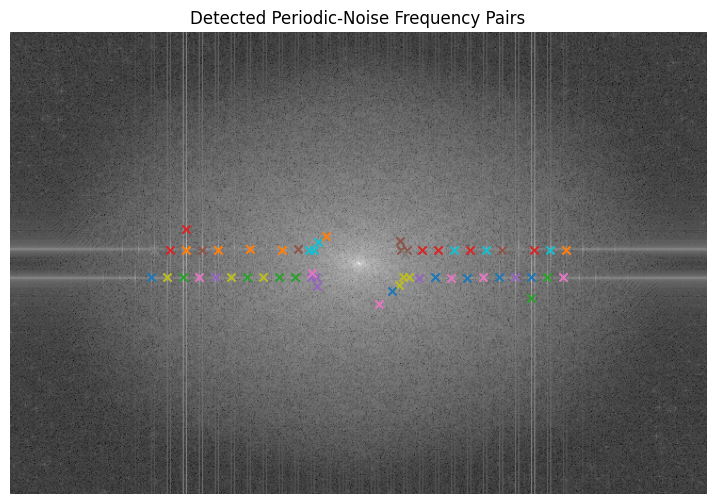

In [25]:
# Detect strong local maxima outside the low-frequency center.
rows, cols = world_magnitude.shape
center_r, center_c = rows // 2, cols // 2

yy, xx = np.ogrid[:rows, :cols]
distance_from_center = np.sqrt(
    (yy - center_r) ** 2 + (xx - center_c) ** 2
)

peak_search = world_magnitude.copy()

# Ignore the central low-frequency area, which mainly contains useful
# large-scale image information rather than periodic interference.
MIN_PEAK_RADIUS = 40
peak_search[distance_from_center < MIN_PEAK_RADIUS] = 0

# Locate local spectral maxima.
local_maxima = (
    peak_search
    == ndimage.maximum_filter(peak_search, size=7)
)

peak_coordinates = np.argwhere(local_maxima)
peak_values = peak_search[local_maxima]

# Sort the candidate peaks from strongest to weakest.
order = np.argsort(peak_values)[::-1]
peak_coordinates = peak_coordinates[order]

# Keep one representative from each symmetric pair and avoid selecting
# several almost identical neighboring maxima.
selected_offsets = []
MIN_PEAK_SEPARATION = 4
MAX_NOTCH_PAIRS = 30

for row, col in peak_coordinates:
    dr = int(row - center_r)
    dc = int(col - center_c)

    if np.hypot(dr, dc) < MIN_PEAK_RADIUS:
        continue

    # Normalize the sign so that each conjugate-symmetric pair appears once.
    if dr < 0 or (dr == 0 and dc < 0):
        dr, dc = -dr, -dc

    is_new_peak = all(
        np.hypot(dr - old_dr, dc - old_dc) > MIN_PEAK_SEPARATION
        for old_dr, old_dc in selected_offsets
    )

    if is_new_peak:
        selected_offsets.append((dr, dc))

    if len(selected_offsets) >= MAX_NOTCH_PAIRS:
        break

print("Selected Butterworth notch pairs:", len(selected_offsets))
print(selected_offsets)

plt.figure(figsize=(10, 6))
plt.imshow(world_magnitude, cmap="gray")

for dr, dc in selected_offsets:
    plt.scatter(center_c + dc, center_r + dr, marker="x", s=35)
    plt.scatter(center_c - dc, center_r - dr, marker="x", s=35)

plt.title("Detected Periodic-Noise Frequency Pairs")
plt.axis("off")
plt.show()

## 11.4 Butterworth Notch-Reject Mask

A smooth Butterworth notch-reject response is constructed around every detected symmetric frequency pair.

Using smooth Butterworth transitions avoids the abrupt frequency cuts associated with ideal notch filters.

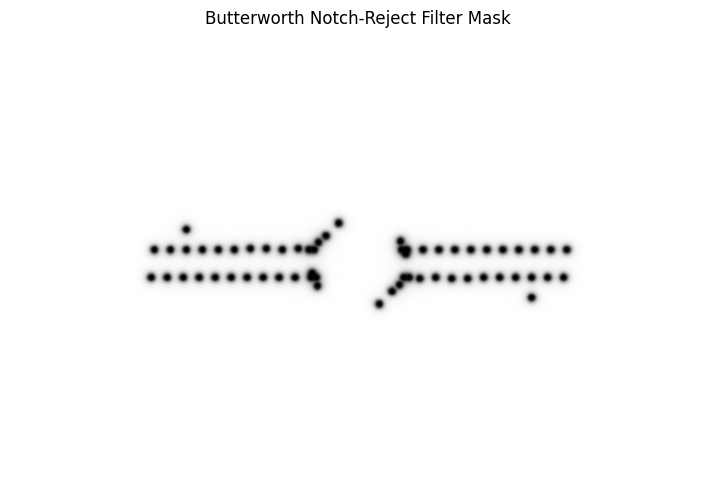

In [26]:
def butterworth_notch_reject(shape, offsets, notch_radius=4.0, order=2):
    rows, cols = shape
    center_r, center_c = rows // 2, cols // 2

    y, x = np.ogrid[:rows, :cols]
    mask = np.ones((rows, cols), dtype=np.float64)

    eps = 1e-12

    for dr, dc in offsets:
        # Distance from the positive-frequency notch center.
        d_positive = np.sqrt(
            (y - (center_r + dr)) ** 2
            + (x - (center_c + dc)) ** 2
        )

        # Distance from the conjugate-symmetric notch center.
        d_negative = np.sqrt(
            (y - (center_r - dr)) ** 2
            + (x - (center_c - dc)) ** 2
        )

        positive_notch = 1.0 / (
            1.0 + (notch_radius / (d_positive + eps)) ** (2 * order)
        )

        negative_notch = 1.0 / (
            1.0 + (notch_radius / (d_negative + eps)) ** (2 * order)
        )

        mask *= positive_notch * negative_notch

    return mask


NOTCH_RADIUS = 4.0
BUTTERWORTH_ORDER = 2

butterworth_mask = butterworth_notch_reject(
    world_gray.shape,
    selected_offsets,
    notch_radius=NOTCH_RADIUS,
    order=BUTTERWORTH_ORDER
)

plt.figure(figsize=(10, 6))
plt.imshow(butterworth_mask, cmap="gray", vmin=0, vmax=1)
plt.title("Butterworth Notch-Reject Filter Mask")
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 6))
plt.imshow(butterworth_mask, cmap="gray", vmin=0, vmax=1)
plt.title("Butterworth Notch-Reject Filter Mask")
plt.axis("off")
plt.savefig(
    RESULTS_DIR / "frequency_domain" / "butterworth_notch_mask.png",
    dpi=150,
    bbox_inches="tight"
)
plt.close()

## 11.5 Frequency-Domain Filtering and Reconstruction

The shifted Fourier spectrum is multiplied by the Butterworth notch-reject mask.

The inverse Fourier transform is then used to reconstruct the filtered image in the spatial domain.

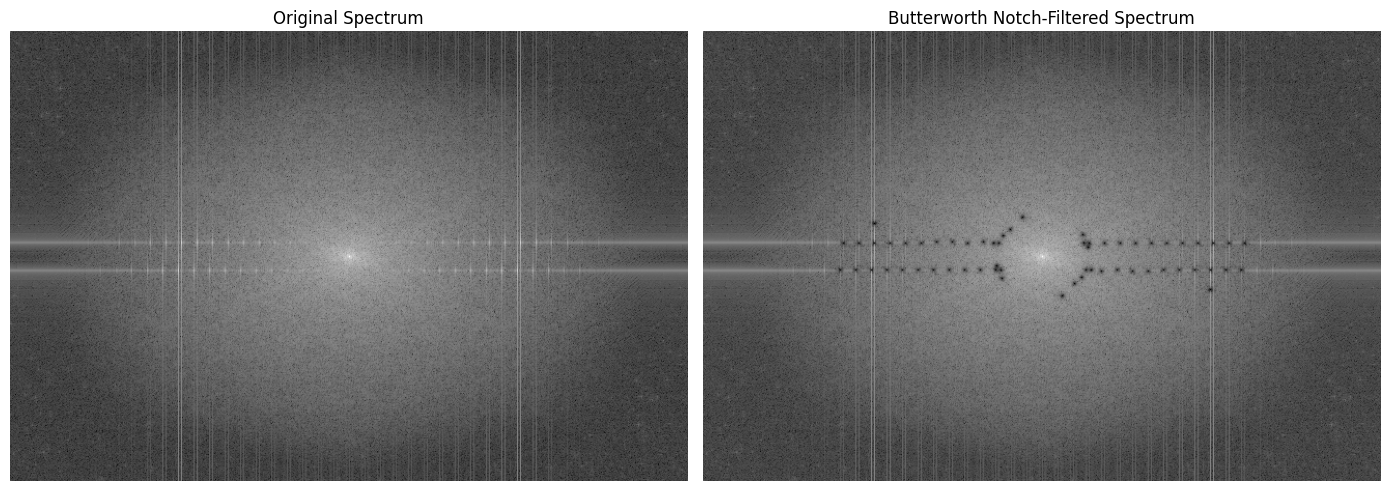

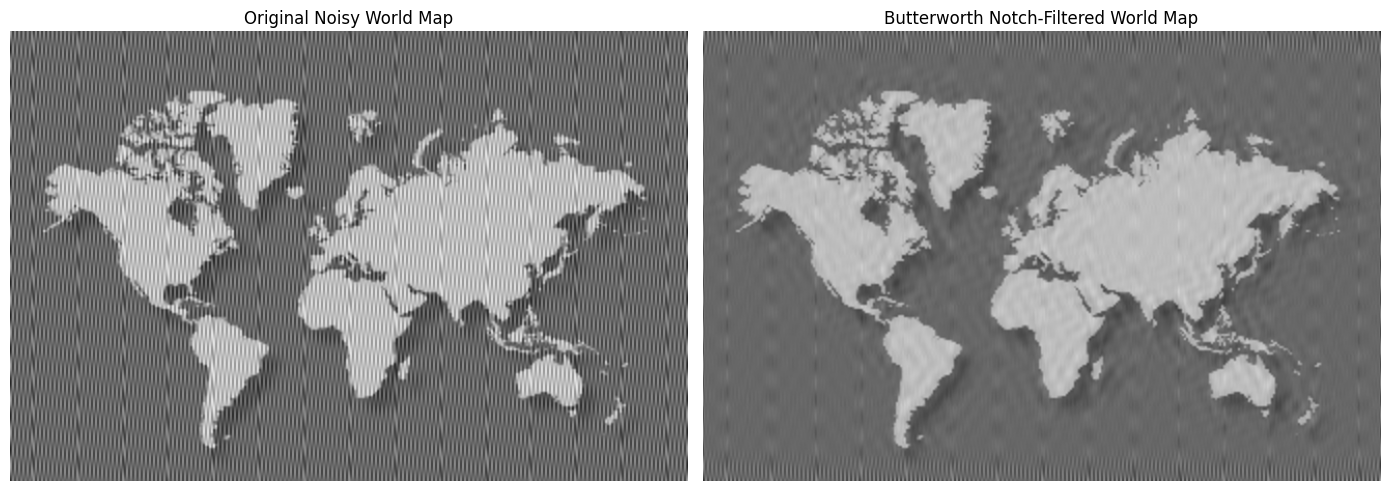

In [27]:
filtered_fft_shifted = world_fft_shifted * butterworth_mask

filtered_fft = np.fft.ifftshift(filtered_fft_shifted)
world_reconstructed = np.fft.ifft2(filtered_fft)

world_denoised = np.real(world_reconstructed)
world_denoised = np.clip(world_denoised, 0, 255)

filtered_magnitude = np.log1p(np.abs(filtered_fft_shifted))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(world_magnitude, cmap="gray")
axes[0].set_title("Original Spectrum")

axes[1].imshow(filtered_magnitude, cmap="gray")
axes[1].set_title("Butterworth Notch-Filtered Spectrum")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(world_gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Noisy World Map")

axes[1].imshow(world_denoised, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Butterworth Notch-Filtered World Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Image.fromarray(world_denoised.astype(np.uint8)).save(
    RESULTS_DIR / "frequency_domain" / "world_map_denoised.png"
)

---

# 12. Results Summary

The project demonstrated the main techniques requested by the assignment:

- RGB and HSV channel visualization
- grayscale and binary conversion
- histogram-based threshold segmentation
- geometric transformations
- Gaussian noise generation
- manual 5×5 averaging filtering
- SciPy convolution
- 8-connected component labeling
- South America extraction
- Fourier-spectrum analysis
- Butterworth notch-reject filtering

## 12.1 Selected Final Results

The most important final results are stored automatically in the repository's `results/` directory when the notebook is executed.

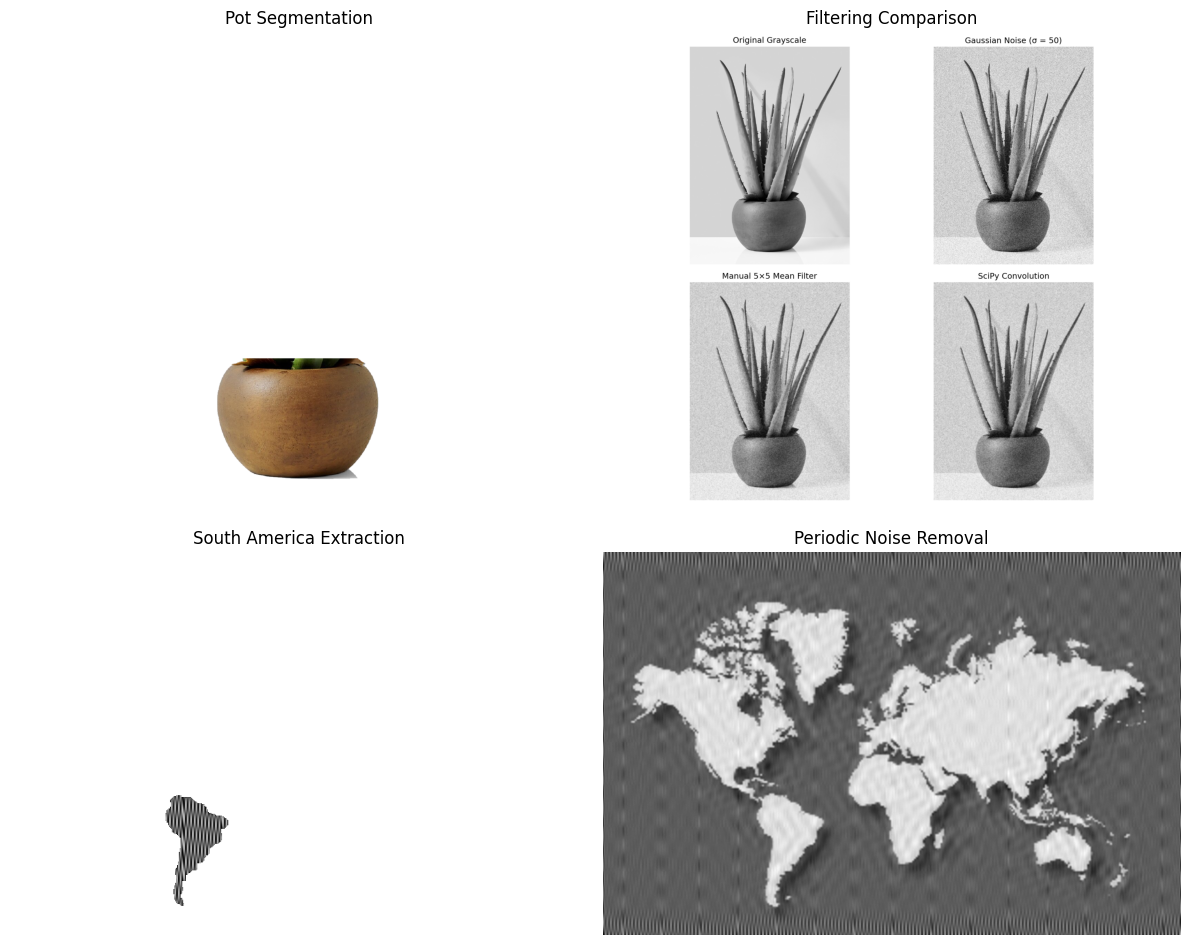

In [28]:
selected_results = [
    ("Pot Segmentation", RESULTS_DIR / "segmentation" / "pot_segmentation.png"),
    ("Filtering Comparison", RESULTS_DIR / "filtering" / "filtering_comparison.png"),
    ("South America Extraction", RESULTS_DIR / "segmentation" / "south_america_extraction.png"),
    ("Periodic Noise Removal", RESULTS_DIR / "frequency_domain" / "world_map_denoised.png"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (title, path) in zip(axes.ravel(), selected_results):
    img = Image.open(path)
    ax.imshow(img, cmap="gray" if np.asarray(img).ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

---

# 13. Conclusions

This project provides a practical implementation of core Digital Image Processing techniques using Python and Jupyter Notebook.

The exercises cover both spatial-domain and frequency-domain processing, including color-space transformations, histogram-based segmentation, geometric transformations, noise modeling, convolution filtering, connected-component analysis, and Fourier-domain periodic-noise removal.

The manual implementation of the 5×5 averaging filter demonstrates the underlying operation of spatial filtering before comparison with SciPy's convolution function.

The project is intentionally structured as a university implementation and remains close to the scope of the original course assignment.